# AQUIRE under gate-level noise: estimates against the exact value

This notebook makes the estimate-vs-truth figure of the AQUIRE accuracy study. It runs AQUIRE
([arXiv:2605.00682](https://arxiv.org/abs/2605.00682)) on the paper's own test system, the periodic
qutrit plaquette, under several gate-level noise models of increasing strength. It then plots each
estimate and its noise-aware error bar against the exact value, and each estimate's error divided by
its error bar.

How it works:

* AQUIRE runs as in the paper: H⁴ diagnostics, one diagnostic shot per measurement shot, and the
  systematic error of Eq. 8b. Each diagnostic shot starts from a random computational basis state
  (App. D of the paper) and fails if its outcome differs from the circuit's ideal output. With
  `DIAGNOSTIC_MODE = "zero"`, every diagnostic shot starts from |0…0⟩ instead.
* The noise is simulated outside AQUIRE. `noise_models.GateNoiseSimulator` computes the exact noisy
  outcome probabilities of every measurement and diagnostic circuit. AQUIRE draws its shots from
  those probabilities through the `outcome_distribution_function` setting.
* Each noise model is a short file in `noise_models/`. All of them have the same error rate per
  gate, set relative to the paper's fitted rates ($\xi_{\rm loc}$ ≈ 0.41% per single-qudit gate, $\xi_{\rm ent}$ ≈ 7.9%
  per entangling gate), so they differ only in the *type* of error.

**Run time.** Each run takes about a minute. The full figure is 5 models × 4 strengths × 2
commutation modes × 8 repeats = 320 runs: about 3 hours on 2 cores, or under 1 hour on 8.
Finished runs are saved in `results.jsonl` and skipped when the notebook is run again. Set
`QUICK = True` for a 5-minute version (one strength, one repeat, fewer shots).

In [1]:
import os
import sys

# Work from this notebook's folder, also when the kernel starts at the repository root (VS Code in
# SympleQ does). The folder goes on sys.path so that the parallel workers can import experiment.
if os.path.isdir("scripts/examples/notebooks/aquire_noise_models"):
    os.chdir("scripts/examples/notebooks/aquire_noise_models")
sys.path.insert(0, os.getcwd())

import experiment                      # before numba is imported: sets NUMBA_NUM_THREADS=1
import numpy as np
import matplotlib.pyplot as plt

from noise_models import MODELS, matched_infidelity, process_infidelity
from noise_models.simulator import P_ENTANGLING
from plaquette import plaquette_hamiltonian, product_state

QUICK = False                                     # True: a quick check of the whole pipeline
STRENGTHS = [1.0] if QUICK else [0.125, 0.25, 0.5, 1.0]   # x the paper's fitted error rates
REPEATS = 1 if QUICK else 8                       # runs per (model, strength, commutation mode)
SHOTS = (100, 1000) if QUICK else (100, 1000, 10000)      # AQUIRE's update steps; the figure uses the last
WORKERS = min(8, os.cpu_count() or 1)
RESULTS = "results_quick.jsonl" if QUICK else "results.jsonl"
DIAGNOSTIC_MODE = "random"   # "random": random computational inputs (App. D); "zero": every diagnostic from |0...0>

## The system

The periodic plaquette of a 2D U(1) lattice gauge theory on three qutrits, at $g^2 = 0.01$. It has 86
Pauli strings besides the identity, as in the paper. The state is the hardware state of the paper,
$(|0\rangle+|1\rangle+|2\rangle)^{\otimes 3}/\sqrt{27}$. The identity string is not measured, so the
exact value below is that of the 86 measured strings.

In [2]:
H, psi = plaquette_hamiltonian(d=3, g2=0.01), product_state(d=3)
M = H.to_hilbert_space()
M = M.toarray() if hasattr(M, "toarray") else np.asarray(M)
print(f"{H.n_paulis()} Pauli strings, exact <O> = {np.real(psi.conj() @ M @ psi):.3f}")

86 Pauli strings, exact <O> = -229.630


## The noise models

| model | what happens after every gate (on the gate's qudits) |
|---|---|
| `uniform` | AQUIRE's own model (Eq. F1): the whole outcome is random with probability ξ(C) |
| `depolarising` | the qudits are replaced by the maximally mixed state with probability p |
| `over_rotation` | a fixed rotation exp(−iθ(X+X†)/2) of each qudit |
| `dephasing` | the qudits' coherences are destroyed with probability p |
| `phase_error` | a fixed phase rotation exp(−iθ diag(k−1)) of each qudit |

At strength *s*, every per-gate model has the process infidelity of local depolarising noise with
probability *s* × the paper's fitted rate: $\xi_{\rm ent}$ = *s* × 7.9% per entangling gate and
$\xi_{\rm loc}$ = *s* × 0.41% per single-qudit gate. The figures show the strength as $\xi_{\rm ent}$. The
paper's quoted hardware fidelity of 98.5% per entangling gate corresponds to *s* ≈ 0.19, or
$\xi_{\rm ent}$ ≈ 1.5%. The check below computes each model's infidelity per
gate numerically and compares it with the target.

In [3]:
for name, Model in MODELS.items():
    model = Model(strength=1.0)
    print(model.describe())
    if name != "uniform":                         # the uniform model acts on whole circuits, not per gate
        print("   infidelity per gate (local, entangling):",
              [f"{process_infidelity(model, 3, k):.5f}" for k in ("local", "entangling")],
              " target:", [f"{matched_infidelity(1.0, 3, k):.5f}" for k in ("local", "entangling")])

uniform: p_local=0.00410, p_entangling=0.0790
depolarising: p_local=0.00410, p_entangling=0.0790
   infidelity per gate (local, entangling): ['0.00364', '0.07802']  target: ['0.00364', '0.07802']
over_rotation: theta_local=0.0854, theta_entangling=0.284
   infidelity per gate (local, entangling): ['0.00364', '0.07802']  target: ['0.00364', '0.07802']
dephasing: p_local=0.00547, p_entangling=0.0878
   infidelity per gate (local, entangling): ['0.00364', '0.07802']  target: ['0.00364', '0.07802']
phase_error: theta_local=0.0740, theta_entangling=0.246
   infidelity per gate (local, entangling): ['0.00364', '0.07802']  target: ['0.00364', '0.07802']


## Run AQUIRE

`experiment.run_one(model, strength, mode, repeat, shots, diagnostic_mode)` is a single run.
`experiment.run_grid` runs every combination in parallel, appends each finished run to `RESULTS` and
returns the saved runs of the grid. Runs are saved with their diagnostic mode, so zero-mode and
random-mode runs are kept apart. Seeds depend only on the commutation mode and the repeat, so all
models, strengths and diagnostic modes are compared on the same random allocation.

In [4]:
runs = experiment.run_grid(list(MODELS), STRENGTHS, REPEATS, shots=SHOTS, path=RESULTS, workers=WORKERS,
                           diagnostic_mode=DIAGNOSTIC_MODE)
print(f"{len(runs)} runs; mean run time {np.mean([r['seconds'] for r in runs]):.0f} s")

320 runs to do, 0 already saved in results.jsonl


  16/320 done (318 s)
  32/320 done (555 s)
  48/320 done (754 s)
  64/320 done (988 s)
  80/320 done (1209 s)
  96/320 done (1468 s)
  112/320 done (1679 s)
  128/320 done (1887 s)
  144/320 done (2159 s)
  160/320 done (2369 s)
  176/320 done (2629 s)
  192/320 done (2813 s)
  208/320 done (3067 s)
  224/320 done (3317 s)
  240/320 done (3556 s)
  256/320 done (3799 s)
  272/320 done (4023 s)
  288/320 done (4264 s)
  304/320 done (4500 s)
  320/320 done (4678 s)
320 runs; mean run time 116 s


## The figure

The figures use the paper's notation: $\langle\hat{O}\rangle$ is the exact value, $\widetilde{O}$ AQUIRE's estimate,
$\widetilde{\Delta O}_{\rm e}$ its noise-aware error bar (Eq. 8a) and $\widetilde{O}_{\rm e} - \widetilde{O}$ the
systematic part of it (Eq. 8b).

For each model (columns), commutation mode (rows) and $\xi_{\rm ent}$ (horizontal axis), at the largest number of
shots:

* **Faint dots:** single runs, as $(\widetilde{O} - \langle\hat{O}\rangle)/|\langle\hat{O}\rangle|$ in %.
* **Marker with bar:** their mean, with the mean of $\widetilde{\Delta O}_{\rm e}$ (1σ) around it.
* **Black line:** the exact value $\langle\hat{O}\rangle$.

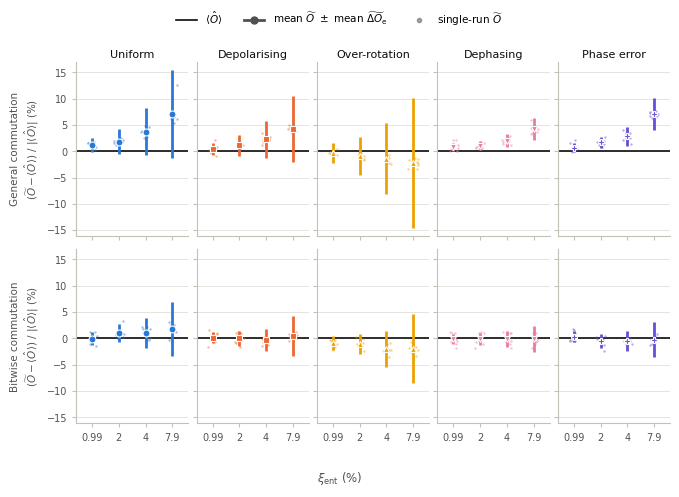

In [5]:
COLOUR = {"uniform": "#2a78d6", "depolarising": "#eb6834", "over_rotation": "#eda100",
          "dephasing": "#e87ba4", "phase_error": "#6250d6"}
MARKER = {"uniform": "o", "depolarising": "s", "over_rotation": "^", "dephasing": "v",
          "phase_error": "P"}
LABEL = {"uniform": "Uniform", "depolarising": "Depolarising", "over_rotation": "Over-rotation",
         "dephasing": "Dephasing", "phase_error": "Phase error"}
INK, INK2, GRID, BASE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"


def xi_ent(strength):
    """The noise strength as xi_ent, the paper's error probability per entangling gate, in %."""
    return 100 * strength * P_ENTANGLING


def plot_estimates_vs_truth(runs, models, strengths, filename="aquire_estimates_vs_truth"):
    final = max(max(r["shots"]) for r in runs)
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(2, len(models), figsize=(1.2 * len(models) + 0.9, 5.0), sharex=True, sharey=True,
                             squeeze=False)
    for row, mode in enumerate(("general", "quditwise")):
        for col, model in enumerate(models):
            ax = axes[row, col]
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
            for side in ("left", "bottom"):
                ax.spines[side].set_color(BASE)
            ax.tick_params(colors=INK2, labelsize=7, length=3, color=BASE)
            ax.grid(True, axis="y", color=GRID, lw=0.6, zorder=0)
            ax.axhline(0, color=INK, lw=1.2, zorder=2)
            for x, s in enumerate(strengths):
                sel = [r for r in runs if r["model"] == model and r["mode"] == mode and r["strength"] == s
                       and max(r["shots"]) == final]
                if not sel:
                    continue
                k = sel[0]["shots"].index(final)
                rel = np.array([100 * (r["estimate"][k] - r["exact"]) / abs(r["exact"]) for r in sel])
                bar = np.mean([100 * r["error_bar"][k] / abs(r["exact"]) for r in sel])
                ax.plot(x + rng.uniform(-0.18, 0.18, len(rel)), rel, ".", ms=3.5, color=COLOUR[model], alpha=0.45,
                        mec="none", zorder=3)
                ax.errorbar([x], [rel.mean()], yerr=[bar], fmt=MARKER[model], ms=5, color=COLOUR[model],
                            mec="#fcfcfb", mew=0.8, elinewidth=2, capsize=0, zorder=4)
            if row == 0:
                ax.set_title(LABEL[model], fontsize=8, color=INK, pad=3)
            ax.set_xticks(range(len(strengths)))
            ax.set_xticklabels([f"{xi_ent(s):.2g}" for s in strengths], fontsize=7)
            ax.set_xlim(-0.6, len(strengths) - 0.4)
        axes[row, 0].set_ylabel(("General" if mode == "general" else "Bitwise") + " commutation\n"
                                r"$(\widetilde{O} - \langle\hat{O}\rangle)\ /\ |\langle\hat{O}\rangle|$ (%)",
                                fontsize=7.5, color=INK2)
    fig.supxlabel(r"$\xi_{\rm ent}$ (%)", fontsize=8.5, color=INK2, y=0.035)
    handles = [plt.Line2D([], [], color=INK, lw=1.2, label=r"$\langle\hat{O}\rangle$"),
               plt.Line2D([], [], color=INK2, marker="o", ms=5, lw=2,
                          label=r"mean $\widetilde{O}\ \pm$ mean $\widetilde{\Delta O}_{\rm e}$"),
               plt.Line2D([], [], color=INK2, marker=".", ms=6, lw=0, alpha=0.5, label=r"single-run $\widetilde{O}$")]
    fig.legend(handles=handles, loc="upper center", ncol=3, frameon=False, fontsize=7.5)
    fig.tight_layout(rect=(0, 0.03, 1, 0.94), h_pad=0.6, w_pad=0.3)
    for ext in ("pdf", "png"):
        fig.savefig(f"{filename}.{ext}", dpi=200)
    return fig


plot_estimates_vs_truth(runs, list(MODELS), STRENGTHS)
plt.show()

## Normalised errors

A second plot of the same runs, at the largest number of shots, with all the noise models on one set of axes and
one panel per commutation mode. The horizontal axis is $\xi_{\rm ent}$ on a log scale. The dotted line marks the
$\xi_{\rm ent}$ whose per-gate infidelity is 1.5%, the paper's quoted hardware fidelity of 98.5% per entangling gate.

Each panel shows $(\widetilde{O} - \langle\hat{O}\rangle)/\widetilde{\Delta O}_{\rm e}$ for each run (faint dots),
and its mean over the repeats (markers). The shaded bands mark ±1 and ±2. The models are offset slightly along
the horizontal axis so they do not overlap.

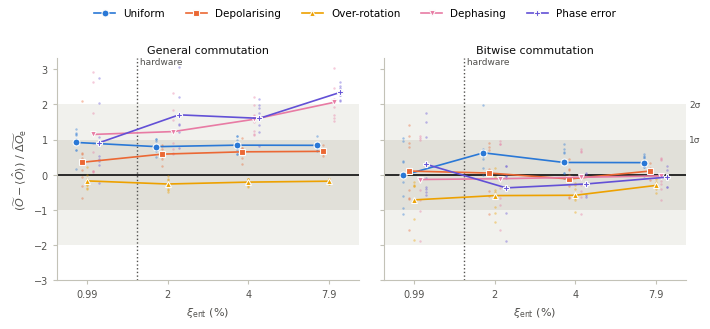

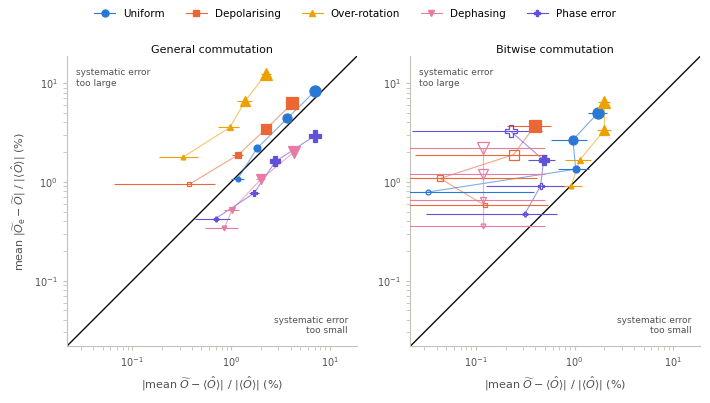

In [6]:
# xi_ent at which the per-gate infidelity is 1.5%: the paper's quoted fidelity of 98.5% per entangling gate
HARDWARE_XI_ENT = xi_ent(0.015 / matched_infidelity(1.0, 3, "entangling"))
MODE_TITLE = {"general": "General commutation", "quditwise": "Bitwise commutation"}


def final_errors(runs, model, mode, strength):
    """Per run, at the largest number of shots, in % of |<O>|: estimate - exact and AQUIRE's error bar."""
    final = max(max(r["shots"]) for r in runs)
    rows = []
    for r in runs:
        if (r["model"], r["mode"], r["strength"]) == (model, mode, strength) and max(r["shots"]) == final:
            k, scale = r["shots"].index(final), 100 / abs(r["exact"])
            rows.append((scale * (r["estimate"][k] - r["exact"]), scale * r["error_bar"][k]))
    return np.array(rows).reshape(-1, 2).T


def style_axes(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(BASE)
    ax.tick_params(colors=INK2, labelsize=7, length=3, color=BASE, which="both")


def xi_ent_axis(ax, strengths):
    """Log x axis of xi_ent, with the hardware value marked."""
    values = [xi_ent(s) for s in strengths]
    ax.set_xscale("log")
    ax.set_xlim(min(values + [HARDWARE_XI_ENT]) / 1.3, max(values) * 1.3)
    ax.set_xticks(values)
    ax.set_xticklabels([f"{v:.2g}" for v in values])
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.axvline(HARDWARE_XI_ENT, color=INK2, ls=":", lw=1, zorder=1)
    ax.text(HARDWARE_XI_ENT, 1, " hardware", transform=ax.get_xaxis_transform(), fontsize=6.5, color=INK2,
            ha="left", va="top")
    ax.set_xlabel(r"$\xi_{\rm ent}$ (%)", fontsize=8, color=INK2)


def plot_normalised_errors(runs, models, strengths, filename="aquire_normalised_errors"):
    """Each run's (estimate - exact) / AQUIRE's error bar, against the error rate per CX gate."""
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.3), sharey=True)
    for ax, mode in zip(axes, ("general", "quditwise")):
        style_axes(ax)
        ax.axhspan(-2, 2, color=GRID, alpha=0.45, lw=0, zorder=0)
        ax.axhspan(-1, 1, color=GRID, lw=0, zorder=0)
        ax.axhline(0, color=INK, lw=1.2, zorder=2)
        for i, model in enumerate(models):
            dodge = 1.05 ** (i - (len(models) - 1) / 2)        # spreads the models apart along the log axis
            xs, means = [], []
            for s in strengths:
                err, bar = final_errors(runs, model, mode, s)
                if not len(err):
                    continue
                z, x = err / bar, xi_ent(s) * dodge
                ax.plot(np.full(len(z), x), z, ".", ms=3.5, color=COLOUR[model], alpha=0.4, mec="none", zorder=3)
                xs.append(x)
                means.append(z.mean())
            ax.plot(xs, means, "-", marker=MARKER[model], ms=5, lw=1.2, color=COLOUR[model], mec="#fcfcfb", mew=0.8,
                    zorder=4, label=LABEL[model])
        xi_ent_axis(ax, strengths)
        ax.set_title(MODE_TITLE[mode], fontsize=8, color=INK, pad=3)
    lo, hi = axes[0].get_ylim()
    axes[0].set_ylim(min(lo, -3), max(hi, 3))
    for level in (1, 2):
        axes[1].text(1.01, level, f"{level}σ", transform=axes[1].get_yaxis_transform(), fontsize=6.5, color=INK2,
                     va="center")
    axes[0].set_ylabel(r"$(\widetilde{O} - \langle\hat{O}\rangle)\ /\ \widetilde{\Delta O}_{\rm e}$", fontsize=8,
                       color=INK2)
    fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=len(models), frameon=False,
               fontsize=7.5)
    fig.tight_layout(rect=(0, 0, 1, 0.92), w_pad=1.5)
    for ext in ("pdf", "png"):
        fig.savefig(f"{filename}.{ext}", dpi=200)
    return fig


plot_normalised_errors(runs, list(MODELS), STRENGTHS)
plt.show()